# Heart Disease Risk Detection — Exploratory Data Analysis

**Dataset:** UCI Heart Disease, Cleveland subset (303 patients, 13 predictors + target).  
**Source:** [UCI ML Repository, dataset 45](https://archive.ics.uci.edu/dataset/45/heart+disease) — original investigators Detrano et al., Cleveland Clinic Foundation, 1988.  
**Local file:** `data/raw/processed.cleveland.data`, an unmodified copy of the official archive. The missing-value token is `?`.

> **What the target means.** The original `num` column is the angiographic disease status: 0 = less than 50% diameter narrowing; 1–4 = greater than 50% narrowing in at least one major vessel. This project detects **presence of coronary artery disease at examination**, not the probability of developing heart disease in the future.

This notebook checks the data quality, describes the cohort, examines class balance and outliers, and justifies the preprocessing used in `ml/train.py`. All figures are also written to `artifacts/plots/`.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Import the project module regardless of the kernel's working directory.
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "ml" / "dataset.py").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.dataset import (
    ARTIFACTS_DIR,
    CATEGORICAL_FEATURES,
    FEATURE_NAMES,
    FEATURE_SCHEMA_BY_KEY,
    NUMERIC_FEATURES,
    PLOTS_DIR,
    load_raw_dataset,
    prepare_dataset,
)

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

INK = "#16302b"
TEAL = "#0f5c50"
TEAL_LIGHT = "#7fb3a4"
CORAL = "#c4553b"
GOLD = "#c99a3f"
MUTED = "#7b8b84"
GRID = "#dfe6e1"

sns.set_theme(style="white", context="notebook")
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.labelsize": 10,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 10,
        "legend.frameon": False,
    }
)


def style_axes(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)

## 1. Load and structurally validate the official file

In [2]:
raw = load_raw_dataset()
print(f"Rows: {raw.shape[0]}, columns: {raw.shape[1]} (13 predictors + target)")
display(raw.head())

assert raw.shape == (303, 14)
assert raw.isna().sum().sum() == 6
print("Structural checks passed: 303 records, 14 columns, 6 missing cells.")

Rows: 303, columns: 14 (13 predictors + target)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Structural checks passed: 303 records, 14 columns, 6 missing cells.


### Data types and codebook

Every field is stored numerically in the supplied file, including categorical fields. The codes below are the **original UCI Cleveland codes** and are kept throughout the project. We deliberately do not use the modified Kaggle-style encodings (for example Kaggle's `cp` 0–3 or `thal` 0–3).

In [3]:
dtype_table = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "non_null": raw.notna().sum(),
        "unique_values": [sorted(raw[c].dropna().unique().tolist()) if raw[c].nunique() < 12 else "continuous" for c in raw.columns],
        "model_role": ["predictor"] * 13 + ["target"],
    }
)
display(dtype_table)

,dtype,non_null,unique_values,model_role
age,float64,303,continuous,predictor
sex,float64,303,"[0.0, 1.0]",predictor
cp,float64,303,"[1.0, 2.0, 3.0, 4.0]",predictor
trestbps,float64,303,continuous,predictor
chol,float64,303,continuous,predictor
fbs,float64,303,"[0.0, 1.0]",predictor
restecg,float64,303,"[0.0, 1.0, 2.0]",predictor
thalach,float64,303,continuous,predictor
exang,float64,303,"[0.0, 1.0]",predictor
oldpeak,float64,303,continuous,predictor


| Variable | Definition | Coding used |
| --- | --- | --- |
| `age` | Age in years | continuous |
| `sex` | Biological sex | 0 = female, 1 = male |
| `cp` | Chest pain type | 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| `trestbps` | Resting systolic blood pressure (mm Hg) | continuous |
| `chol` | Serum cholesterol (mg/dL) | continuous |
| `fbs` | Fasting blood sugar > 120 mg/dL | 0 = no, 1 = yes |
| `restecg` | Resting ECG result | 0 normal, 1 ST-T abnormality, 2 probable/definite LVH |
| `thalach` | Maximum heart rate achieved (bpm) | continuous |
| `exang` | Exercise-induced angina | 0 = no, 1 = yes |
| `oldpeak` | Exercise-induced ST depression relative to rest | continuous (mm) |
| `slope` | Slope of peak-exercise ST segment | 1 upsloping, 2 flat, 3 downsloping |
| `ca` | Major vessels coloured by fluoroscopy | 0–3, **4 missing** |
| `thal` | Thallium stress test | 3 normal, 6 fixed defect, 7 reversible defect, **2 missing** |
| `num` | Angiographic disease status | 0 = <50% narrowing; 1–4 = >50% narrowing |

Source: `data/raw/heart-disease.names`. `ca` and `thal` are the only fields with missing values.

## 2. Missing values

,missing_count,missing_percent
ca,4,1.32
thal,2,0.66


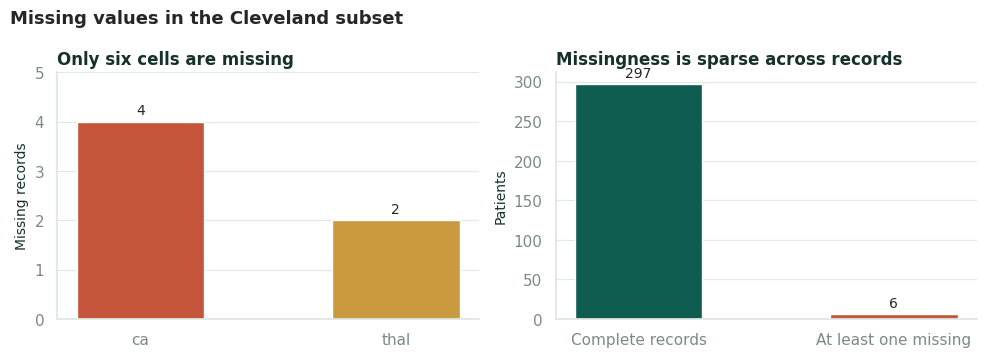

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [4]:
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(raw) * 100).round(2)
missing = missing[missing["missing_count"] > 0]
display(missing)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
bars = ax.bar(missing.index, missing["missing_count"], color=[CORAL, GOLD], width=0.5)
ax.bar_label(bars, padding=3)
ax.set_ylim(0, 5)
ax.set_ylabel("Missing records")
ax.set_title("Only six cells are missing", loc="left")
style_axes(ax)

ax = axes[1]
status = pd.Series(
    {"Complete records": int(raw.notna().all(axis=1).sum()), "At least one missing": int(raw.isna().any(axis=1).sum())}
)
bars = ax.bar(status.index, status.values, color=[TEAL, CORAL], width=0.5)
ax.bar_label(bars, padding=3)
ax.set_ylabel("Patients")
ax.set_title("Missingness is sparse across records", loc="left")
style_axes(ax)
fig.suptitle("Missing values in the Cleveland subset", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_missingness.png", dpi=180, bbox_inches="tight")
plt.show()

display(raw[raw.isna().any(axis=1)])

**Decision:** drop neither rows nor columns. Deleting the four `ca` rows and two `thal` rows would discard 2% of a small cohort. Missing values will instead be imputed **inside the scikit-learn pipeline**, fitted on training folds only: median for numeric variables (including `ca`) and most frequent for categorical variables (including `thal`). This prevents leakage from the test set. The six incomplete rows remain valid examples for all other attributes.

## 3. Target distribution and class imbalance

num,0,1,2,3,4
original_num,164,55,36,35,13


disease,0,1
binary_target,164.0,139.0
percent,54.1,45.9


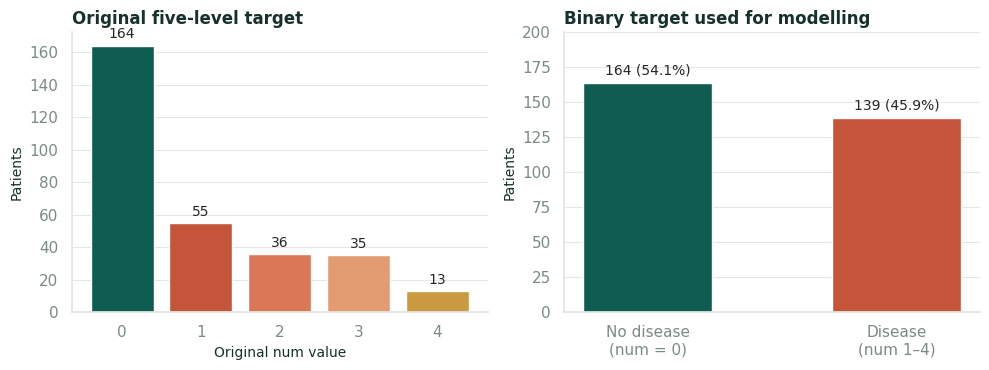

In [5]:
original_counts = raw["num"].value_counts().sort_index()
X, y = prepare_dataset(raw)
binary_counts = y.value_counts().sort_index()

display(pd.DataFrame({"original_num": original_counts}).T)
display(pd.DataFrame({"binary_target": binary_counts, "percent": (binary_counts / len(raw) * 100).round(1)}).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
bars = ax.bar([str(i) for i in original_counts.index], original_counts.values, color=[TEAL, CORAL, "#d97757", "#e39b72", GOLD])
ax.bar_label(bars, padding=3)
ax.set_xlabel("Original num value")
ax.set_ylabel("Patients")
ax.set_title("Original five-level target", loc="left")
style_axes(ax)

ax = axes[1]
bars = ax.bar(["No disease\n(num = 0)", "Disease\n(num 1–4)"], binary_counts.values, color=[TEAL, CORAL], width=0.52)
ax.bar_label(bars, labels=[f"{v} ({v / len(raw):.1%})" for v in binary_counts.values], padding=4)
ax.set_ylim(0, 200)
ax.set_ylabel("Patients")
ax.set_title("Binary target used for modelling", loc="left")
style_axes(ax)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_class_balance.png", dpi=180, bbox_inches="tight")
plt.show()

The binary target is moderately balanced: **164 (54.1%) without disease** and **139 (45.9%) with disease**. The majority baseline accuracy is therefore 54.1%, so accuracy alone would be a weak summary. The class balance is mild enough that resampling is not justified for a dataset this small; class weighting was nevertheless explored as a Logistic Regression and tree hyperparameter. All splits and cross-validation folds are stratified.

## 4. Descriptive statistics and unusual values

In [6]:
display(raw.describe().T.round(2))

outlier_rows = []
for column in NUMERIC_FEATURES:
    values = raw[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((values < low) | (values > high)).sum()
    outlier_rows.append(
        {
            "feature": column,
            "q1": round(q1, 2),
            "q3": round(q3, 2),
            "IQR_lower": round(low, 2),
            "IQR_upper": round(high, 2),
            "outliers": int(count),
            "percent": round(count / len(values) * 100, 1),
        }
    )
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

# Basic plausibility checks rather than assuming the classic UCI zeros are present.
plausibility = {
    "cholesterol == 0": int((raw["chol"] == 0).sum()),
    "resting BP == 0": int((raw["trestbps"] == 0).sum()),
    "max heart rate == 0": int((raw["thalach"] == 0).sum()),
    "age < 18": int((raw["age"] < 18).sum()),
    "oldpeak < 0": int((raw["oldpeak"] < 0).sum()),
}
print(json.dumps(plausibility, indent=2))

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


,feature,q1,q3,IQR_lower,IQR_upper,outliers,percent
0,age,48.0,61.0,28.50,80.50,0,0.0
1,trestbps,120.0,140.0,90.00,170.00,9,3.0
2,chol,211.0,275.0,115.00,371.00,5,1.7
3,thalach,133.5,166.0,84.75,214.75,1,0.3
4,oldpeak,0.0,1.6,-2.40,4.00,5,1.7
5,ca,0.0,1.0,-1.50,2.50,20,6.7


{
  "cholesterol == 0": 0,
  "resting BP == 0": 0,
  "max heart rate == 0": 0,
  "age < 18": 0,
  "oldpeak < 0": 0
}


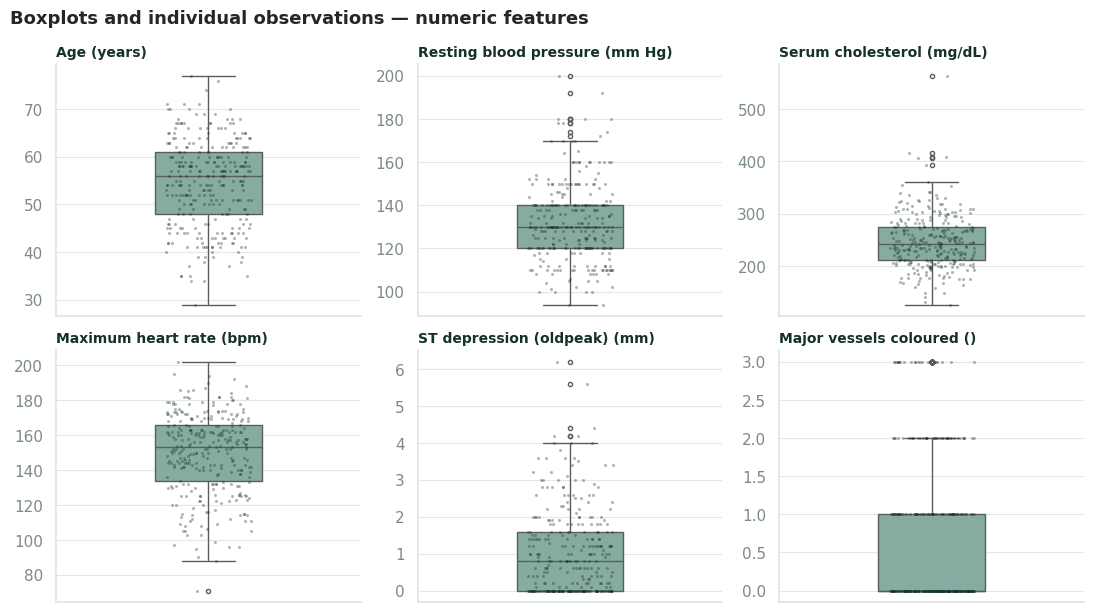

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for ax, column in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.boxplot(y=raw[column], color=TEAL_LIGHT, width=0.35, fliersize=3, linewidth=1, ax=ax)
    sns.stripplot(y=raw[column], color=INK, size=2.2, alpha=0.35, jitter=0.14, ax=ax)
    label = FEATURE_SCHEMA_BY_KEY[column]["label"]
    unit = FEATURE_SCHEMA_BY_KEY[column]["unit"] or ""
    ax.set_title(f"{label} ({unit})", loc="left", fontsize=10)
    ax.set_ylabel("")
    style_axes(ax)
    ax.grid(axis="y", color=GRID)
fig.suptitle("Boxplots and individual observations — numeric features", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_outliers.png", dpi=180, bbox_inches="tight")
plt.show()

**Outlier decision:** the IQR rule flags a modest number of observations, mostly high cholesterol, high maximum heart rate, and ST depression values. These are physiologically plausible and the cohort contains no impossible zeros. Removing them would bias the model against unusual patients and shrink an already small sample. The pipeline therefore keeps all records; numeric scaling reduces scale sensitivity, and the tree-based models can accommodate non-linear tails. Outliers are flagged here, not treated as errors.

## 5. Feature distributions by disease status

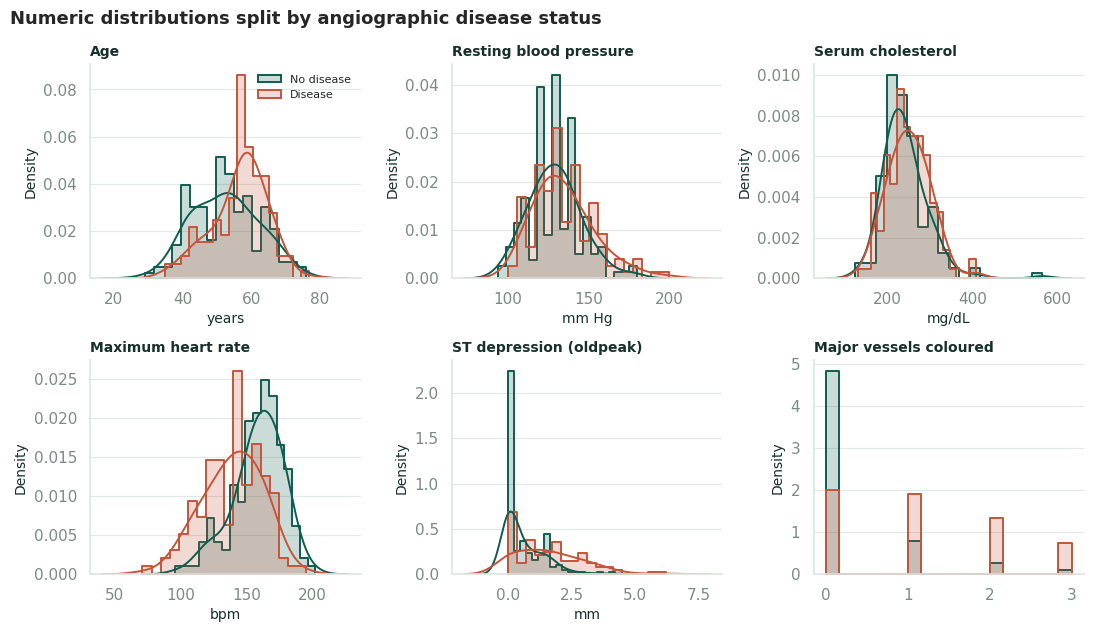

,No disease mean,Disease mean,difference
age,52.59,56.63,4.04
trestbps,129.25,134.57,5.32
chol,242.64,251.47,8.83
thalach,158.38,139.26,-19.12
oldpeak,0.59,1.57,0.99
ca,0.27,1.14,0.86


In [8]:
plot_frame = pd.concat([X, y.rename("disease")], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, column in zip(axes.ravel(), NUMERIC_FEATURES):
    for value, label, color in [(0, "No disease", TEAL), (1, "Disease", CORAL)]:
        subset = plot_frame.loc[plot_frame["disease"] == value, column].dropna()
        sns.histplot(subset, bins=18, stat="density", element="step", fill=True, alpha=0.22, color=color, label=label, ax=ax, linewidth=1.4)
        if subset.nunique() > 5:
            sns.kdeplot(subset, color=color, linewidth=1.4, ax=ax, bw_adjust=1.2)
    ax.set_title(FEATURE_SCHEMA_BY_KEY[column]["label"], loc="left", fontsize=10)
    ax.set_xlabel(FEATURE_SCHEMA_BY_KEY[column]["unit"] or "")
    ax.set_ylabel("Density")
    style_axes(ax)
    ax.grid(axis="y", color=GRID)
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle("Numeric distributions split by angiographic disease status", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_numeric_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

group_means = plot_frame.groupby("disease")[NUMERIC_FEATURES].mean().T
group_means.columns = ["No disease mean", "Disease mean"]
group_means["difference"] = group_means.iloc[:, 1] - group_means.iloc[:, 0]
display(group_means.round(2))

Several patterns are clinically consistent and visible in this cohort:

- Patients with disease tend to have **lower maximum heart rate** during exercise and **higher exercise-induced ST depression** (`oldpeak`).
- `ca` (vessels coloured) and exercise-induced angina skew strongly toward the disease group.
- Age differences are modest; cholesterol differences are not striking, which is a useful reminder that a single risk factor is not a diagnosis.

These are unadjusted group comparisons, not causal estimates.

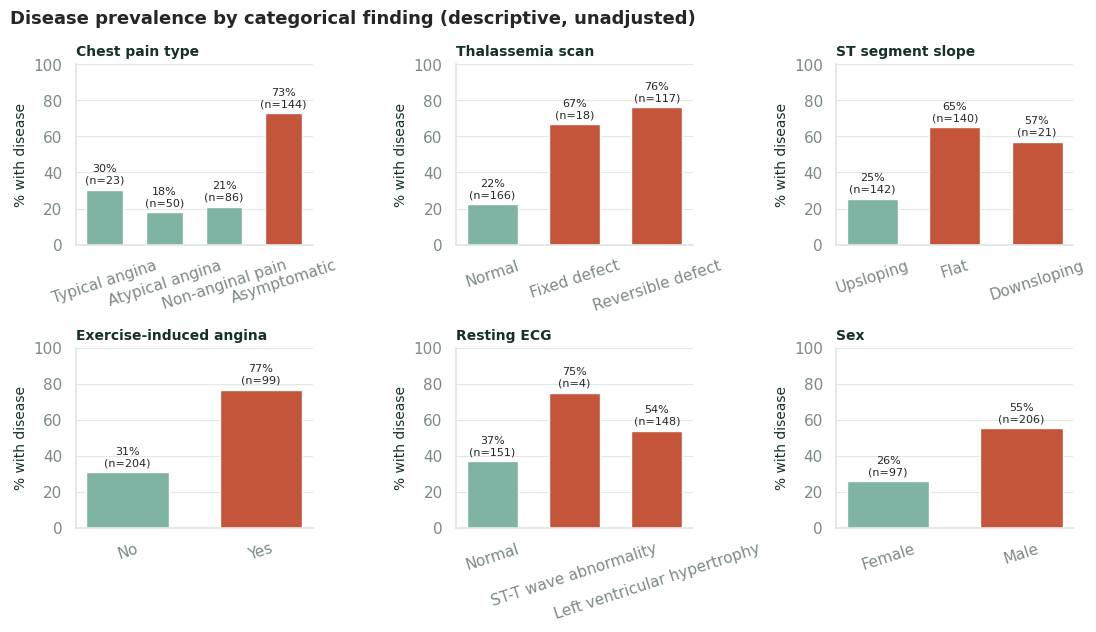

In [9]:
features_to_plot = ["cp", "thal", "slope", "exang", "restecg", "sex"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, feature in zip(axes.ravel(), features_to_plot):
    field = FEATURE_SCHEMA_BY_KEY[feature]
    labels = [option["label"] for option in field["options"]]
    values = [option["value"] for option in field["options"]]
    rates = [plot_frame.loc[plot_frame[feature] == value, "disease"].mean() * 100 for value in values]
    counts = [int((plot_frame[feature] == value).sum()) for value in values]
    bars = ax.bar(labels, rates, color=[TEAL_LIGHT if rate < 50 else CORAL for rate in rates], width=0.62)
    ax.bar_label(bars, labels=[f"{rate:.0f}%\n(n={count})" for rate, count in zip(rates, counts)], padding=3, fontsize=8)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% with disease")
    ax.set_title(field["label"], loc="left", fontsize=10)
    ax.tick_params(axis="x", labelrotation=18)
    style_axes(ax)
fig.suptitle("Disease prevalence by categorical finding (descriptive, unadjusted)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_categorical_rates.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Correlation structure

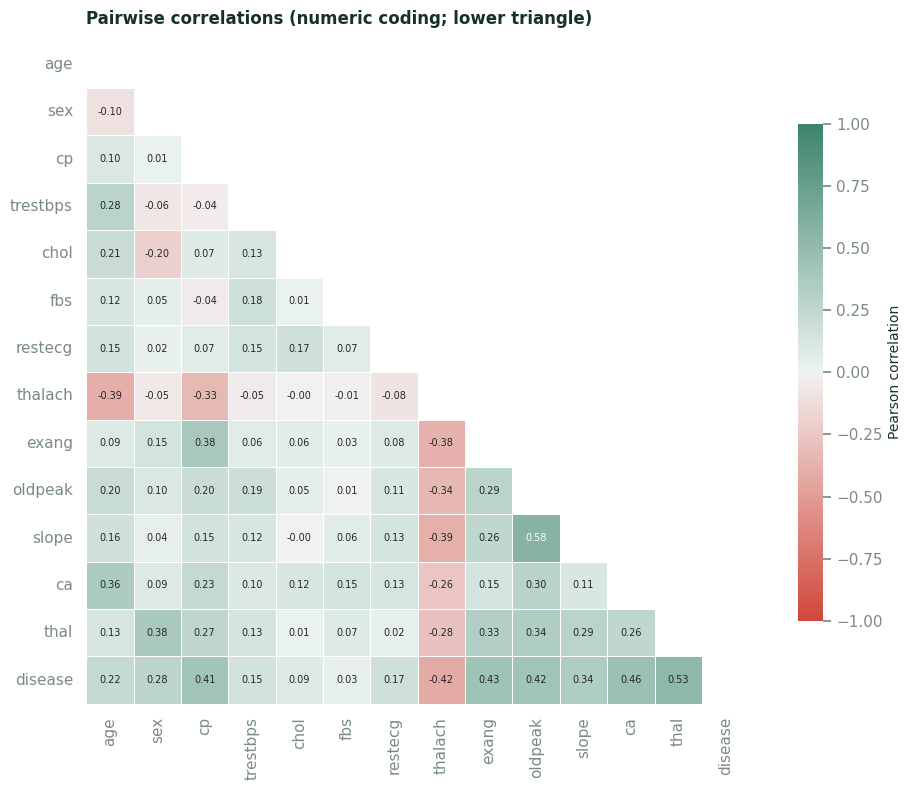

,correlation_with_disease
thal,0.526
ca,0.460
exang,0.432
oldpeak,0.425
thalach,-0.417
cp,0.414
slope,0.339
sex,0.277
age,0.223
restecg,0.169


In [10]:
corr_frame = pd.concat([X, y.rename("disease")], axis=1)
corr = corr_frame.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10.5, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap=sns.diverging_palette(15, 160, as_cmap=True),
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation"},
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    ax=ax,
)
ax.set_title("Pairwise correlations (numeric coding; lower triangle)", loc="left", pad=12)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_correlation.png", dpi=180, bbox_inches="tight")
plt.show()

target_corr = corr["disease"].drop("disease").sort_values(key=abs, ascending=False)
display(target_corr.round(3).to_frame("correlation_with_disease"))

Pearson correlation treats categorical codes as ordered numbers, so it is only a screening view. The strongest single associations with disease presence are `ca`, `oldpeak`, `exang`, `thalach` (negative), and `thal` (negative coding relationship). Some predictors are correlated with each other — for example `slope`/`oldpeak` — which can affect individual coefficient interpretation in Logistic Regression. The model is used for prediction, not for causal attribution; regularisation and cross-validation reduce overfitting to these correlations.

## 7. Key relationships and an asymmetry worth noticing

cp_label,Asymptomatic,Atypical angina,Non-anginal,Typical angina
sex_label,,,,
Female,55.0,11.1,2.9,0.0
Male,79.8,21.9,33.3,36.8


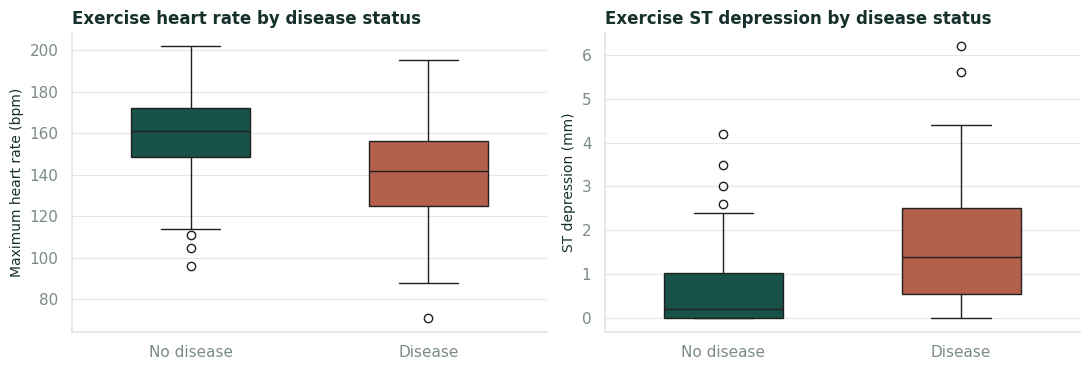

In [11]:
sex_cp = (
    plot_frame.assign(
        sex_label=plot_frame["sex"].map({0: "Female", 1: "Male"}),
        cp_label=plot_frame["cp"].map({1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal", 4: "Asymptomatic"}),
    )
    .groupby(["sex_label", "cp_label"], observed=True)["disease"]
    .agg(["count", "mean"])
    .reset_index()
)
sex_cp["mean"] = (sex_cp["mean"] * 100).round(1)
display(sex_cp.rename(columns={"count": "n", "mean": "disease_%"}).pivot(index="sex_label", columns="cp_label", values="disease_%"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
sns.boxplot(
    data=plot_frame.assign(disease_label=plot_frame["disease"].map({0: "No disease", 1: "Disease"})),
    x="disease_label",
    y="thalach",
    hue="disease_label",
    palette={"No disease": TEAL, "Disease": CORAL},
    legend=False,
    width=0.5,
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Maximum heart rate (bpm)")
ax.set_title("Exercise heart rate by disease status", loc="left")
style_axes(ax)
ax.grid(axis="y", color=GRID)

ax = axes[1]
sns.boxplot(
    data=plot_frame.assign(disease_label=plot_frame["disease"].map({0: "No disease", 1: "Disease"})),
    x="disease_label",
    y="oldpeak",
    hue="disease_label",
    palette={"No disease": TEAL, "Disease": CORAL},
    legend=False,
    width=0.5,
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("ST depression (mm)")
ax.set_title("Exercise ST depression by disease status", loc="left")
style_axes(ax)
ax.grid(axis="y", color=GRID)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_key_relationships.png", dpi=180, bbox_inches="tight")
plt.show()

A note on clinical reasoning: a woman in this 1980s Cleveland cohort with chest pain is a small subgroup, and the `cp` categories are not symmetrical across sexes. This is exactly why subgroup performance should not be assumed from overall metrics, and why the project avoids presenting the output as an individual diagnosis. The dataset is historical and far too small for fairness claims.

## 8. Preprocessing decisions carried into the pipeline

| Decision | Rationale |
| --- | --- |
| Predict `num > 0` as binary | Original `num` 1–4 all mean >50% narrowing in at least one vessel; binarisation matches the standard Cleveland presence-detection task. |
| Keep all 303 rows | Only six cells are missing; dropping rows would waste scarce data. |
| Train/test split: 80/20, stratified, seed 42 | Holds out about 61 patients with the same disease prevalence; fixed seed makes the split reproducible. |
| Median imputation for numeric features (including `ca`) | Robust to skew and outliers; fitted inside the pipeline on training folds only. |
| Most-frequent imputation for categorical `thal` | Small number of missing values; avoids inventing a category with too little evidence. |
| `StandardScaler` for numeric features | Kneaded for Logistic Regression; harmless for tree-based models and keeps a shared preprocessing stage. |
| One-hot encoding for categorical features | `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal` are nominal categories; `handle_unknown="ignore"` keeps serving safe. `ca` is kept numeric because it is a count (0–3). |
| All preprocessing inside `Pipeline`/`ColumnTransformer` | Imputation, scaling and encoding are fitted separately inside each CV fold, so no test or validation information leaks. |
| No SMOTE / resampling | The 54/46 split is close to balanced; synthetic patients in a 303-row medical dataset would be hard to defend. `class_weight` options were explored during tuning instead. |
| 5-fold stratified CV on the training set | More stable than a single validation split at this size. The test set is opened once, after model selection. |
| Select by mean CV F1, tie-break ROC-AUC | F1 balances positive-class recall with false positives; ROC-AUC is threshold-free. Selection never uses test results. |

**Out of scope:** the model does not estimate future heart-disease risk; it outputs a model score for angiographic disease presence at examination. Probability values are not clinically calibrated.

## 9. EDA summary

- The official Cleveland file is structurally sound: 303 × 14, 13 predictors, six missing cells in `ca`/`thal`, and no impossible zeros.
- The binary target is 164 no-disease / 139 disease — mildly balanced, so accuracy needs precision/recall/F1 context.
- Maximum heart rate, exercise-induced ST depression, vessel count, exercise angina, chest-pain type, and thallium result show the clearest unadjusted separation.
- Outliers are plausible physiology; they are retained, with imputation and scaling fitted inside cross-validation.
- The cohort is small, single-centre, and historical. The next stage (`ml/train.py`) compares three models with 5-fold CV and reports one honest held-out evaluation of the selected model.

See `artifacts/metrics.json` for the trained model's real cross-validation and test results, and the **Model Insights** page for the same numbers rendered in the application.